# Notebook 02: Vectorized $k$-NN Voronoi Boundaries, Curse of Dimensionality & Generative Naive Bayes

In this notebook we explore:
1. **Instance-Based Voronoi Tessellations ($k$-NN):** Comparing high-variance $k=1$ Voronoi islands against smoothed $k=15$ majority-vote boundaries using our zero-loop pairwise Euclidean distance matrix.
2. **Generative vs. Discriminative Modeling:** Visualizing how Gaussian Naive Bayes fits axis-aligned class-conditional density ellipses $P(\mathbf{x} \mid y = c) = \mathcal{N}(\boldsymbol{\mu}_c, \mathrm{diag}(\boldsymbol{\sigma}_c^2))$ and induces a quadratic conic-section decision boundary, compared against a linear discriminative hyperplane.
3. **Empirical Proof of the Curse of Dimensionality:** Measuring pairwise distance concentration $\frac{D_{\max} - D_{\min}}{D_{\min}} \to 0$ and hypercube neighborhood edge length $\ell(n) = r^{1/n} \to 1$ as dimension $n$ grows from $2$ to $1024$.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Ensure src package is importable
repo_root = Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.classifiers_engine import (
    GaussianNaiveBayesScratch,
    KNNScratch,
    LinearSVMScratch,
    pairwise_sq_dists_vectorized,
)
from src.plot_theme import (
    AMBER,
    CORAL,
    CYAN,
    EMERALD,
    PURPLE,
    SLATE_BLUE,
    TEXT_MUTED,
    apply_github_dark_style,
    plot_decision_boundary,
    save_fig,
)

apply_github_dark_style()

## 1. Generating a Two-Class Dataset with Distinct Class Variances

Class $0$ is compact ($\sigma_0 = 0.55$) while Class $1$ is broadly dispersed along $x_1$ and $x_2$ ($\sigma_1 = [1.35, 1.15]$), plus a few noisy overlap points.

In [2]:
rng = np.random.default_rng(2026)
m0, m1 = 90, 90
X_c0 = rng.normal(loc=[-0.9, -0.7], scale=[0.55, 0.55], size=(m0, 2))
X_c1 = rng.normal(loc=[0.95, 0.85], scale=[1.35, 1.15], size=(m1, 2))
X_data = np.vstack([X_c0, X_c1])
y_data = np.concatenate([np.zeros(m0, dtype=np.int64), np.ones(m1, dtype=np.int64)])

knn_1 = KNNScratch(k=1).fit(X_data, y_data)
knn_15 = KNNScratch(k=15, weights="distance").fit(X_data, y_data)
gnb = GaussianNaiveBayesScratch().fit(X_data, y_data)
svm_disc = LinearSVMScratch(C=1.0, learning_rate=0.05, epochs=800).fit(X_data, y_data)

for name, clf in [
    ("1-NN (High Variance Voronoi)", knn_1),
    ("15-NN (Smoothed Neighborhood)", knn_15),
    ("Gaussian Naive Bayes (Generative Quadratic)", gnb),
    ("Linear SVM (Discriminative Hyperplane)", svm_disc),
]:
    acc = float(np.mean(clf.predict(X_data) == y_data))
    print(f"{name:<45} | Training Accuracy: {acc*100:.2f}%")

1-NN (High Variance Voronoi)                  | Training Accuracy: 100.00%
15-NN (Smoothed Neighborhood)                 | Training Accuracy: 100.00%
Gaussian Naive Bayes (Generative Quadratic)   | Training Accuracy: 93.89%
Linear SVM (Discriminative Hyperplane)        | Training Accuracy: 88.33%


## 2. Simulating the Curse of Dimensionality in $\mathbb{R}^n$ ($n \in [2, 1024]$)

In [3]:
dims = [2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]
rel_contrasts = []
edge_lengths_1pct = [0.01 ** (1.0 / d) for d in dims]

for d in dims:
    pts = rng.uniform(0.0, 1.0, size=(400, d))
    D = np.sqrt(pairwise_sq_dists_vectorized(pts, pts))
    # Mask self-distances on diagonal
    np.fill_diagonal(D, np.nan)
    d_min = np.nanmin(D, axis=1)
    d_max = np.nanmax(D, axis=1)
    rel_contrasts.append(float(np.mean((d_max - d_min) / d_min)))

print("\nCurse of Dimensionality Diagnostics:")
for d, rc, el in zip(dims[::2], rel_contrasts[::2], edge_lengths_1pct[::2]):
    print(f"  Dimension n={d:4d} | Relative Distance Contrast (D_max - D_min)/D_min = {rc:6.3f} | 1%-Volume Hypercube Side = {el*100:5.1f}%")


Curse of Dimensionality Diagnostics:
  Dimension n=   2 | Relative Distance Contrast (D_max - D_min)/D_min = 58.304 | 1%-Volume Hypercube Side =  10.0%
  Dimension n=   8 | Relative Distance Contrast (D_max - D_min)/D_min =  3.140 | 1%-Volume Hypercube Side =  56.2%
  Dimension n=  32 | Relative Distance Contrast (D_max - D_min)/D_min =  0.839 | 1%-Volume Hypercube Side =  86.6%
  Dimension n= 128 | Relative Distance Contrast (D_max - D_min)/D_min =  0.336 | 1%-Volume Hypercube Side =  96.5%
  Dimension n= 512 | Relative Distance Contrast (D_max - D_min)/D_min =  0.153 | 1%-Volume Hypercube Side =  99.1%


## 3. 2x2 Comparison Dashboard (`02_generative_vs_discriminative_boundaries.png`)

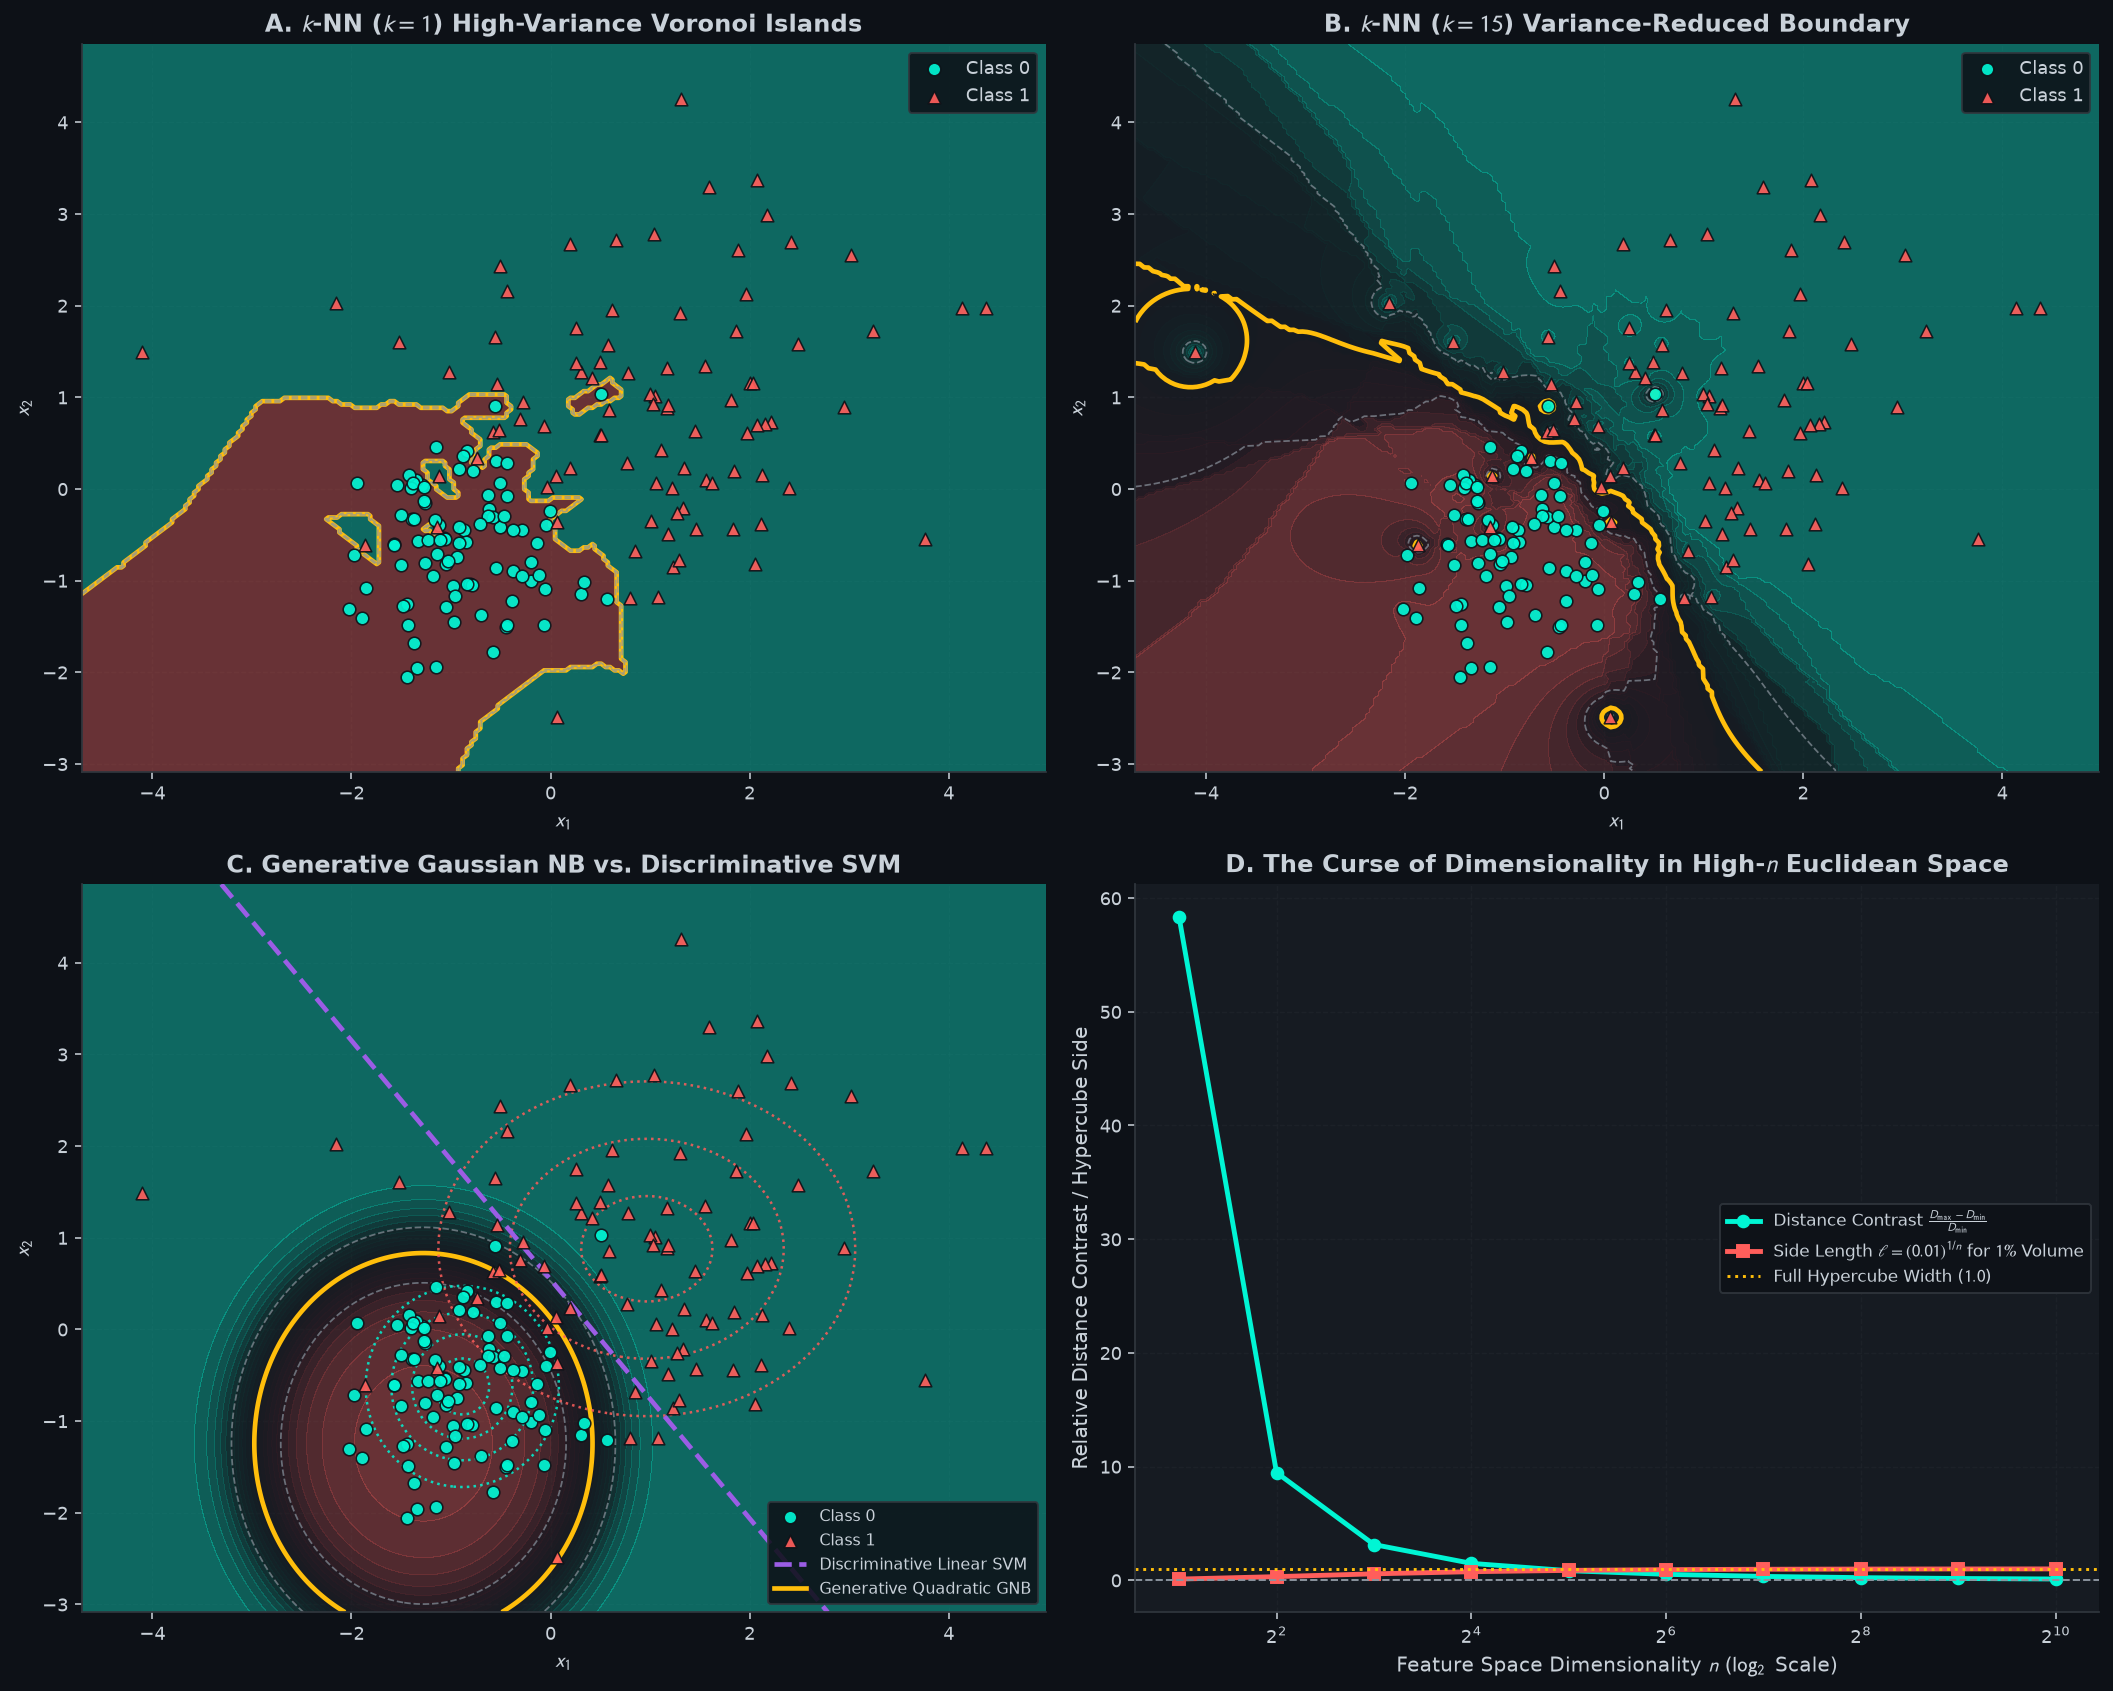

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15.2, 12.2))

# Panel A: 1-NN Voronoi Tessellation
plot_decision_boundary(
    predict_fn=lambda grid: knn_1.predict_proba(grid)[:, 1],
    X=X_data,
    y=y_data,
    ax=axes[0, 0],
    title="A. $k$-NN ($k=1$) High-Variance Voronoi Islands",
)

# Panel B: 15-NN Smoothed Boundary
plot_decision_boundary(
    predict_fn=lambda grid: knn_15.predict_proba(grid)[:, 1],
    X=X_data,
    y=y_data,
    ax=axes[0, 1],
    title="B. $k$-NN ($k=15$) Variance-Reduced Boundary",
)

# Panel C: Generative Gaussian Naive Bayes (with Class Density Ellipses) vs Discriminative SVM Line
ax3 = axes[1, 0]
plot_decision_boundary(
    predict_fn=lambda grid: gnb.predict_proba(grid)[:, 1],
    X=X_data,
    y=y_data,
    ax=ax3,
    title="C. Generative Gaussian NB vs. Discriminative SVM",
)

# Overlay generative class-conditional Gaussian density ellipses P(x | y=c) and Linear SVM boundary
x1_g = np.linspace(X_data[:, 0].min() - 0.6, X_data[:, 0].max() + 0.6, 180)
x2_g = np.linspace(X_data[:, 1].min() - 0.6, X_data[:, 1].max() + 0.6, 180)
XX1, XX2 = np.meshgrid(x1_g, x2_g)
grid_c = np.c_[XX1.ravel(), XX2.ravel()]
log_j = gnb.predict_log_joint(grid_c)
ax3.contour(XX1, XX2, np.exp(log_j[:, 0]).reshape(XX1.shape), levels=4, colors=[CYAN], linestyles=":", linewidths=1.3, alpha=0.85)
ax3.contour(XX1, XX2, np.exp(log_j[:, 1]).reshape(XX1.shape), levels=4, colors=[CORAL], linestyles=":", linewidths=1.3, alpha=0.85)

svm_dec = svm_disc.decision_function(grid_c).reshape(XX1.shape)
ax3.contour(XX1, XX2, svm_dec, levels=[0.0], colors=[PURPLE], linestyles="--", linewidths=2.4)
ax3.plot([], [], color=PURPLE, linestyle="--", linewidth=2.4, label="Discriminative Linear SVM")
ax3.plot([], [], color=AMBER, linestyle="-", linewidth=2.4, label="Generative Quadratic GNB")
ax3.legend(loc="lower right", fontsize=8.3)

# Panel D: Curse of Dimensionality
ax4 = axes[1, 1]
ax4.semilogx(dims, rel_contrasts, color=CYAN, marker="o", linewidth=2.5, base=2, label=r"Distance Contrast $\frac{D_{\max}-D_{\min}}{D_{\min}}$")
ax4.semilogx(dims, edge_lengths_1pct, color=CORAL, marker="s", linewidth=2.5, base=2, label=r"Side Length $\ell = (0.01)^{1/n}$ for $1\%$ Volume")
ax4.axhline(0.0, color=TEXT_MUTED, linestyle="--", linewidth=1.0)
ax4.axhline(1.0, color=AMBER, linestyle=":", linewidth=1.5, label="Full Hypercube Width ($1.0$)")
ax4.set_xlabel("Feature Space Dimensionality $n$ ($\log_2$ Scale)")
ax4.set_ylabel("Relative Distance Contrast / Hypercube Side")
ax4.set_title("D. The Curse of Dimensionality in High-$n$ Euclidean Space")
ax4.legend(loc="center right", fontsize=8.6)

fig.tight_layout()
assets_dir = Path("assets")
assets_dir.mkdir(parents=True, exist_ok=True)
save_fig(fig, assets_dir / "02_generative_vs_discriminative_boundaries.png")
plt.show()